[All milestones](../START_HERE.ipynb) · [Main solution](../solution/reduced_qubit_hybrid_hourly.ipynb)

# Milestone 2 — classical baseline and cheapest-first heuristic

The MILP is the daily reference. The original cheapest-first heuristic violates a minimum-up constraint; its cost is not a feasible improvement. The violation report is retained.

In [1]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


In [2]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no remote job. Select an environment that already includes it.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    raise ImportError("Use a qBraid environment with qiskit-aer installed.")

import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


## 2. Classical baseline (Milestone 2)

**MILP** (mixed-integer linear program): the standard classical tool for unit commitment. The costs and rules are written as linear equations over on/off variables and outputs, and a solver (HiGHS, inside scipy) finds the provably cheapest schedule. Ours is `solve_milp` in `check.py`, about 60 lines. Read it once.

MILP solved in 0.053 s
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


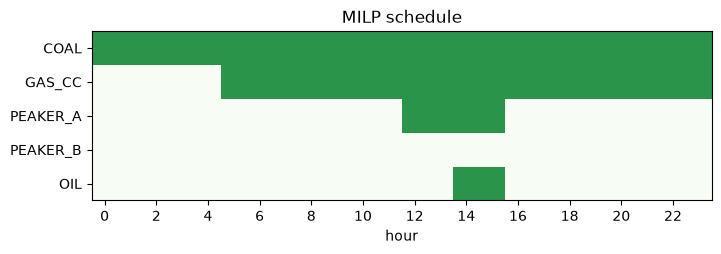

In [3]:
milp_cost, milp_schedule, milp_dispatch, secs = solve_milp(plants, demand, reserve)
print(f"MILP solved in {secs:.3f} s")
milp_result = check_schedule(plants, demand, reserve, milp_schedule, milp_cost=milp_cost)


def plot_schedule(schedule, title, ax=None):
    # Green = on. One row per plant, one column per hour.
    if ax is None:
        ax = plt.subplots(figsize=(8, 2.2))[1]
    ax.imshow(np.asarray(schedule).T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(N), names)
    ax.set_xticks(range(0, len(demand), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    return ax


plot_schedule(milp_schedule, "MILP schedule")
plt.show()

### Cheapest-first rule

A rule a person might use: rank plants by cost per MWh at full output, then each hour switch plants on down the list until capacity covers demand + reserve.

- Cost per MWh at full output = `marginal_cost_per_mwh + no_load_cost_per_h / pmax_mw`.
- `np.argsort(values)` gives plant indices from cheapest to most expensive.
- For each hour `t`, add plants in that order until the sum of their `pmax_mw` is at least `demand[t] + reserve[t]`.

The rule ignores startup costs and min up/down times. Look at what that costs, and which rules it breaks.

Total cost: $330,594  (startups $37,950, no-load $20,288, energy $272,356)
MILP optimum: $327,924   gap: +0.81%
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
    16  PEAKER_B   min up broken    turned off after 2 h on (needs 3)


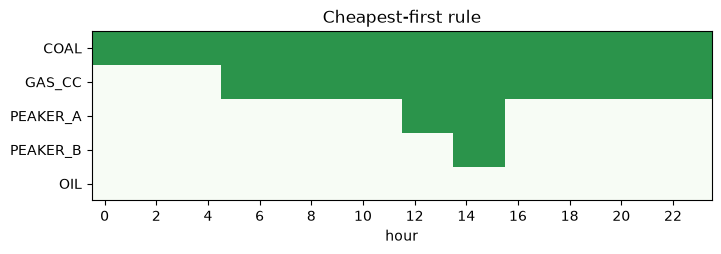

In [4]:
def cheapest_first(plants, demand, reserve):
    schedule = np.zeros((len(demand), len(plants)), dtype=int)

    # Rank plants by cost per MWh at full output.
    costs = [
        p["marginal_cost_per_mwh"]
        + p["no_load_cost_per_h"] / p["pmax_mw"]
        for p in plants
    ]
    order = np.argsort(costs)

    # Turn plants on in that order until capacity is sufficient.
    for t in range(len(demand)):
        capacity = 0.0
        required = demand[t] + reserve[t]

        for i in order:
            if capacity >= required:
                break

            schedule[t, i] = 1
            capacity += plants[i]["pmax_mw"]

    return schedule


rule_schedule = cheapest_first(plants, demand, reserve)
rule_result = check_schedule(plants, demand, reserve, rule_schedule, milp_cost=milp_cost)
plot_schedule(rule_schedule, "Cheapest-first rule")
plt.show()

## Economic dispatch

The MILP returns both on/off commitments and continuous MW outputs. These are separate decisions.

In [5]:
from IPython.display import display, Markdown
rows = ['| Hour | ' + ' | '.join(names) + ' |', '|---|' + '---:|' * N]
for t, output in enumerate(milp_dispatch):
    rows.append('| ' + str(t) + ' | ' + ' | '.join(f'{mw:.2f}' for mw in output) + ' |')
display(Markdown('Dispatch in MW:\n\n' + '\n'.join(rows)))

Dispatch in MW:

| Hour | COAL | GAS_CC | PEAKER_A | PEAKER_B | OIL |
|---|---:|---:|---:|---:|---:|
| 0 | 313.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| 1 | 289.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| 2 | 280.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| 3 | 281.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| 4 | 298.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| 5 | 163.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 6 | 214.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 7 | 268.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 8 | 312.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 9 | 350.00 | 175.00 | 0.00 | 0.00 | 0.00 |
| 10 | 350.00 | 209.00 | 0.00 | 0.00 | 0.00 |
| 11 | 350.00 | 281.00 | 0.00 | 0.00 | 0.00 |
| 12 | 350.00 | 284.00 | 20.00 | 0.00 | 0.00 |
| 13 | 350.00 | 307.00 | 20.00 | 0.00 | 0.00 |
| 14 | 350.00 | 307.00 | 20.00 | 0.00 | 20.00 |
| 15 | 350.00 | 310.00 | 20.00 | 0.00 | 20.00 |
| 16 | 350.00 | 284.00 | 0.00 | 0.00 | 0.00 |
| 17 | 350.00 | 235.00 | 0.00 | 0.00 | 0.00 |
| 18 | 350.00 | 197.00 | 0.00 | 0.00 | 0.00 |
| 19 | 350.00 | 179.00 | 0.00 | 0.00 | 0.00 |
| 20 | 340.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 21 | 280.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 22 | 223.00 | 168.00 | 0.00 | 0.00 | 0.00 |
| 23 | 178.00 | 168.00 | 0.00 | 0.00 | 0.00 |